In [1]:
import pandas as pd
import sys
sys.path.insert(0, "..")

from src.constants import DataFile
from src.paths import raw_file

dfs: dict[str, pd.DataFrame] = {}
for dataset in DataFile:
  dfs[dataset] = pd.read_csv(raw_file(dataset), sep="\t", index_col=0)
  print(dfs[dataset].shape)

(1255, 84)
(60660, 1226)
(1232, 3)
(1247, 193)


In [2]:
import numpy as np

star = dfs[DataFile.STAR_COUNTS]
rows_count = star.shape[0]
(star.notna().sum() != rows_count).sum()
for value in np.arange(0.3, 0.7, 0.1):
  print(((star == 0).sum() / rows_count > value).sum())

# star.T.describe()

1215
1168
179
0


In [3]:
cols_count = star.shape[1]
print((star.min() == 0).sum()/cols_count)
for value in np.arange(1, 10):
  print((star.std() > value).sum()/cols_count)

1.0
1.0
1.0
1.0
0.9632952691680261
0.0
0.0
0.0
0.0
0.0


In [11]:
N=5_000
std = star.std(axis=1)
print(std.min(), std.mean(), std.max())
star_filtered = star.loc[std.nlargest(N).index]
star_t = star_filtered.T
star_t.index = star_t.index.str[:-1]
print(star_t.shape)
print(star_t.head(5))

0.0 0.8595336099045765 5.446751386431819
(1226, 5000)
Ensembl_ID       ENSG00000166509.12  ENSG00000110484.7  ENSG00000153002.12  \
TCGA-D8-A146-01            7.936638          12.757807           19.767711   
TCGA-AQ-A0Y5-01           13.322210          17.646355           13.235715   
TCGA-C8-A274-01           16.939740           1.584963           11.759888   
TCGA-BH-A0BD-01            4.523562          16.133243            3.321928   
TCGA-B6-A1KC-01            7.882643           7.276124            9.828136   

Ensembl_ID       ENSG00000134184.13  ENSG00000160182.3  ENSG00000124935.4  \
TCGA-D8-A146-01            1.000000          15.425085          10.787086   
TCGA-AQ-A0Y5-01           11.066762          10.256209          15.839179   
TCGA-C8-A274-01            1.000000          16.086033           1.000000   
TCGA-BH-A0BD-01            2.000000          10.977995          13.110973   
TCGA-B6-A1KC-01            0.000000           5.209453           5.954196   

Ensembl_ID    

In [5]:
surv = dfs[DataFile.SURVIVAL]
print(surv.head(5))
print(surv.index.str.split('-').str[-1].unique().sort_values())
# 01 = primary tumor, 06 = metastatic, 11 = normal tissue

                  OS.time  OS      _PATIENT
sample                                     
TCGA-C8-A275-01A      1.0   0  TCGA-C8-A275
TCGA-AC-A7VC-01A      1.0   0  TCGA-AC-A7VC
TCGA-BH-A1F8-01A      1.0   1  TCGA-BH-A1F8
TCGA-BH-A1F8-11B      1.0   1  TCGA-BH-A1F8
TCGA-PL-A8LX-01A      5.0   0  TCGA-PL-A8LX
Index(['01A', '01B', '01C', '06A', '11A', '11B'], dtype='object', name='sample')


In [18]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

cl = dfs[DataFile.PAM50_CLINICAL]
print(cl.shape) # 1247 patients
# print(cl["id"].sort_values()) # the same patient may have >1 samples
# print(cl.columns)
# cl.nunique()
cols = cl.columns[cl.columns.str.lower().str.contains("subtype|pam|molecular")]
cl[cols].nunique()
cl[cols].apply(pd.Series.unique)
pam50 = "PAM50Call_RNAseq"
cl[pam50].value_counts()
cl.head(2)

(1247, 193)


,AJCC_Stage_nature2012,Age_at_Initial_Pathologic_Diagnosis_nature2012,CN_Clusters_nature2012,Converted_Stage_nature2012,Days_to_Date_of_Last_Contact_nature2012,Days_to_date_of_Death_nature2012,ER_Status_nature2012,Gender_nature2012,HER2_Final_Status_nature2012,Integrated_Clusters_no_exp__nature2012,Integrated_Clusters_unsup_exp__nature2012,Integrated_Clusters_with_PAM50__nature2012,Metastasis_Coded_nature2012,Metastasis_nature2012,Node_Coded_nature2012,Node_nature2012,OS_Time_nature2012,OS_event_nature2012,PAM50Call_RNAseq,PAM50_mRNA_nature2012,PR_Status_nature2012,RPPA_Clusters_nature2012,SigClust_Intrinsic_mRNA_nature2012,SigClust_Unsupervised_mRNA_nature2012,Survival_Data_Form_nature2012,Tumor_T1_Coded_nature2012,Tumor_nature2012,Vital_Status_nature2012,_INTEGRATION,_PANCAN_CNA_PANCAN_K8,_PANCAN_Cluster_Cluster_PANCAN,_PANCAN_DNAMethyl_BRCA,_PANCAN_DNAMethyl_PANCAN,_PANCAN_RPPA_PANCAN_K8,_PANCAN_UNC_RNAseq_PANCAN_K16,_PANCAN_miRNA_PANCAN,_PANCAN_mirna_BRCA,_PANCAN_mutation_PANCAN,_PATIENT,_cohort,_primary_disease,_primary_site,additional_pharmaceutical_therapy,additional_radiation_therapy,additional_surgery_locoregional_procedure,additional_surgery_metastatic_procedure,age_at_initial_pathologic_diagnosis,anatomic_neoplasm_subdivision,axillary_lymph_node_stage_method_type,axillary_lymph_node_stage_other_method_descriptive_text,bcr_followup_barcode,bcr_patient_barcode,bcr_sample_barcode,breast_cancer_surgery_margin_status,breast_carcinoma_estrogen_receptor_status,breast_carcinoma_immunohistochemistry_er_pos_finding_scale,breast_carcinoma_immunohistochemistry_pos_cell_score,breast_carcinoma_immunohistochemistry_prgstrn_rcptr_ps_fndng_scl,breast_carcinoma_primary_surgical_procedure_name,breast_carcinoma_progesterone_receptor_status,breast_carcinoma_surgical_procedure_name,breast_neoplasm_other_surgical_procedure_descriptive_text,cytokeratin_immunohistochemistry_staining_method_mcrmtstss_ndctr,days_to_additional_surgery_locoregional_procedure,days_to_additional_surgery_metastatic_procedure,days_to_birth,days_to_collection,days_to_death,days_to_initial_pathologic_diagnosis,days_to_last_followup,days_to_last_known_alive,days_to_new_tumor_event_additional_surgery_procedure,days_to_new_tumor_event_after_initial_treatment,disease_code,distant_metastasis_present_ind2,er_detection_method_text,er_level_cell_percentage_category,fluorescence_in_st_hybrdztn_dgnstc_prcdr_chrmsm_17_sgnl_rslt_rng,followup_case_report_form_submission_reason,form_completion_date,gender,her2_and_centromere_17_positive_finding_other_measuremnt_scl_txt,her2_erbb_method_calculation_method_text,her2_erbb_pos_finding_cell_percent_category,her2_erbb_pos_finding_fluorescence_n_st_hybrdztn_clcltn_mthd_txt,her2_immunohistochemistry_level_result,her2_neu_and_centromere_17_copy_number_analysis_npt_ttl_nmbr_cnt,her2_neu_breast_carcinoma_copy_analysis_input_total_number,her2_neu_chromosone_17_signal_ratio_value,her2_neu_metastatic_breast_carcinoma_copy_analysis_inpt_ttl_nmbr,histological_type,histological_type_other,history_of_neoadjuvant_treatment,hr2_n_nd_cntrmr_17_cpy_nmbr_mtsttc_brst_crcnm_nlyss_npt_ttl_nmbr,icd_10,icd_o_3_histology,icd_o_3_site,immunohistochemistry_positive_cell_score,informed_consent_verified,init_pathology_dx_method_other,initial_pathologic_diagnosis_method,initial_weight,is_ffpe,lab_proc_her2_neu_immunohistochemistry_receptor_status,lab_procedure_her2_neu_in_situ_hybrid_outcome_type,lost_follow_up,lymph_node_examined_count,margin_status,menopause_status,metastatic_breast_carcinm_ps_fndng_prgstrn_rcptr_thr_msr_scl_txt,metastatic_breast_carcinom_lb_prc_hr2_n_mmnhstchmstry_rcptr_stts,metastatic_breast_carcinoma_erbb2_immunohistochemistry_levl_rslt,metastatic_breast_carcinoma_estrogen_receptor_detection_mthd_txt,metastatic_breast_carcinoma_estrogen_receptor_status,metastatic_breast_carcinoma_estrogen_receptr_lvl_cll_prcnt_ctgry,metastatic_breast_carcinoma_her2_erbb_method_calculatin_mthd_txt,metastatic_breast_carcinoma_her2_erbb_pos_findng_cll_prcnt_ctgr

In [16]:
print(len(set(star_t.index) & set(cl.index)))
print(star_t.index[:3])
print(cl.index[:3])
merged = star_t.merge(cl, left_index=True, right_index=True, how="left");
merged.shape

1215
Index(['TCGA-D8-A146-01', 'TCGA-AQ-A0Y5-01', 'TCGA-C8-A274-01'], dtype='object')
Index(['TCGA-3C-AAAU-01', 'TCGA-3C-AALI-01', 'TCGA-3C-AALJ-01'], dtype='object', name='sampleID')


(1226, 5193)

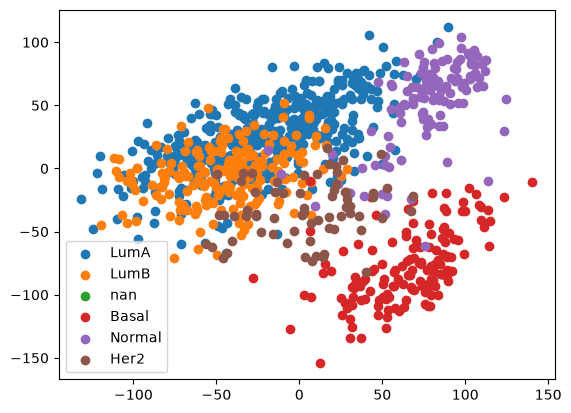

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

labels = merged[pam50]
pca = PCA(n_components=2)
components = pca.fit_transform(star_t)
components.shape
for subtype  in labels.unique():
  mask = labels == subtype
  plt.scatter(x=components[mask, 0], y=components[mask, 1], label=subtype)
plt.legend()